Largest training demand: 229 | Q_MAX = 500


,mean_demand,Q_star,Q_theory,Q_det,test_profit_stoch,test_profit_det,diff_stoch_minus_det,stockout_freq_stoch
0,80,80,80,80,49596.22,49596.22,0.0,0.47
1,100,100,100,100,62827.36,62827.36,0.0,0.47
2,120,120,120,120,76151.06,76151.06,0.0,0.47
3,150,150,150,150,96218.82,96218.82,0.0,0.48
4,180,180,180,180,116375.48,116375.48,0.0,0.48


,case,demand_variance,Q_star,Q_theory,Q_det,det_predicted_profit,test_profit_stoch,diff_stoch_minus_det,diff_ci95_half_width,stockout_freq_stoch,p5_profit_stoch
0,Poisson (var 120),120,120,120,120,84000.0,76151.06,0.00,0.00,0.47,55200.0
1,NegBin (var 240),240,120,119,120,84000.0,72737.72,0.00,0.00,0.47,44000.0
2,NegBin (var 480),480,119,119,120,84000.0,68163.92,26.82,17.63,0.49,30500.0
3,NegBin (var 960),960,117,118,120,84000.0,61466.32,102.42,52.29,0.49,11500.0


,parameter,value,critical_ratio,Q_star,Q_theory,Q_det,exp_profit_train,test_profit_stoch,test_profit_det,diff_stoch_minus_det,diff_ci95_half_width
0,c,600,0.611,123,123,120,100495.72,100425.08,100151.06,274.02,50.855
1,c,700,0.556,121,121,120,88259.24,88205.52,88151.06,54.46,17.618
2,c,800,0.500,120,120,120,76195.60,76151.06,76151.06,0.00,0.000
3,c,900,0.444,118,118,120,64269.24,64242.34,64151.06,91.28,34.590
4,c,1000,0.389,117,117,120,52510.48,52490.24,52151.06,339.18,50.948
5,h,0,0.529,121,121,120,76644.56,76593.41,76586.42,6.99,16.639
6,h,50,0.514,120,120,120,76412.25,76368.74,76368.74,0.00,0.000
7,h,100,0.500,120,120,120,76195.60,76151.06,76151.06,0.00,0.000
8,h,200,0.474,119,119,120,75777.34,75741.76,75715.70,26.06,18.615
9,h,400,0.429,118,118,120,75048.28,75018.14,74844.98,173.16,40.355


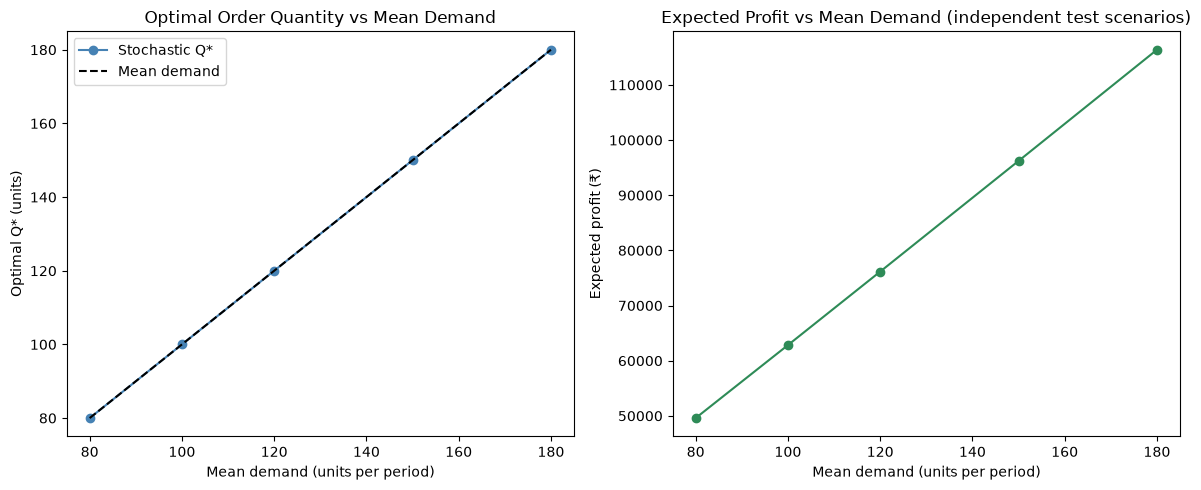

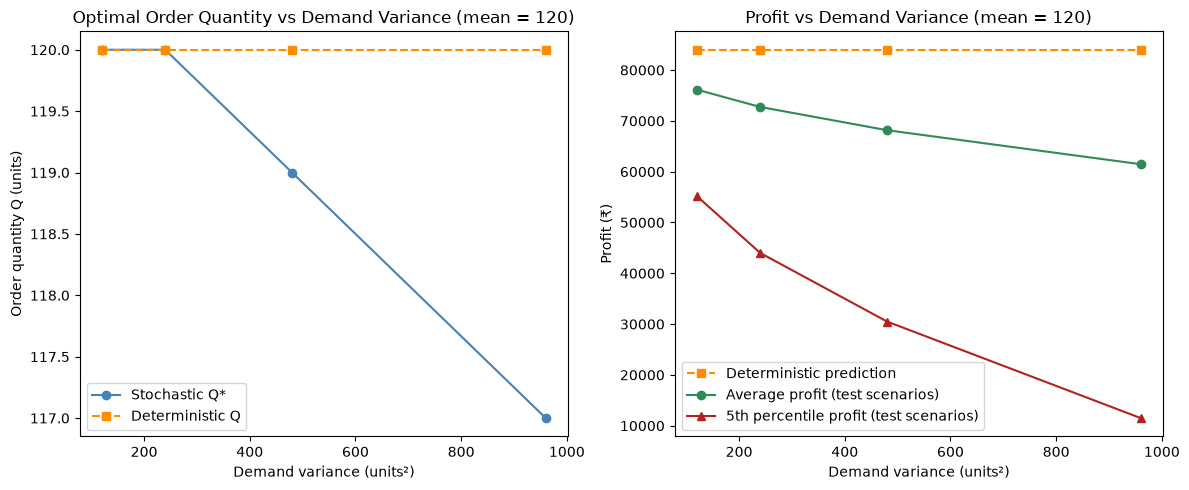

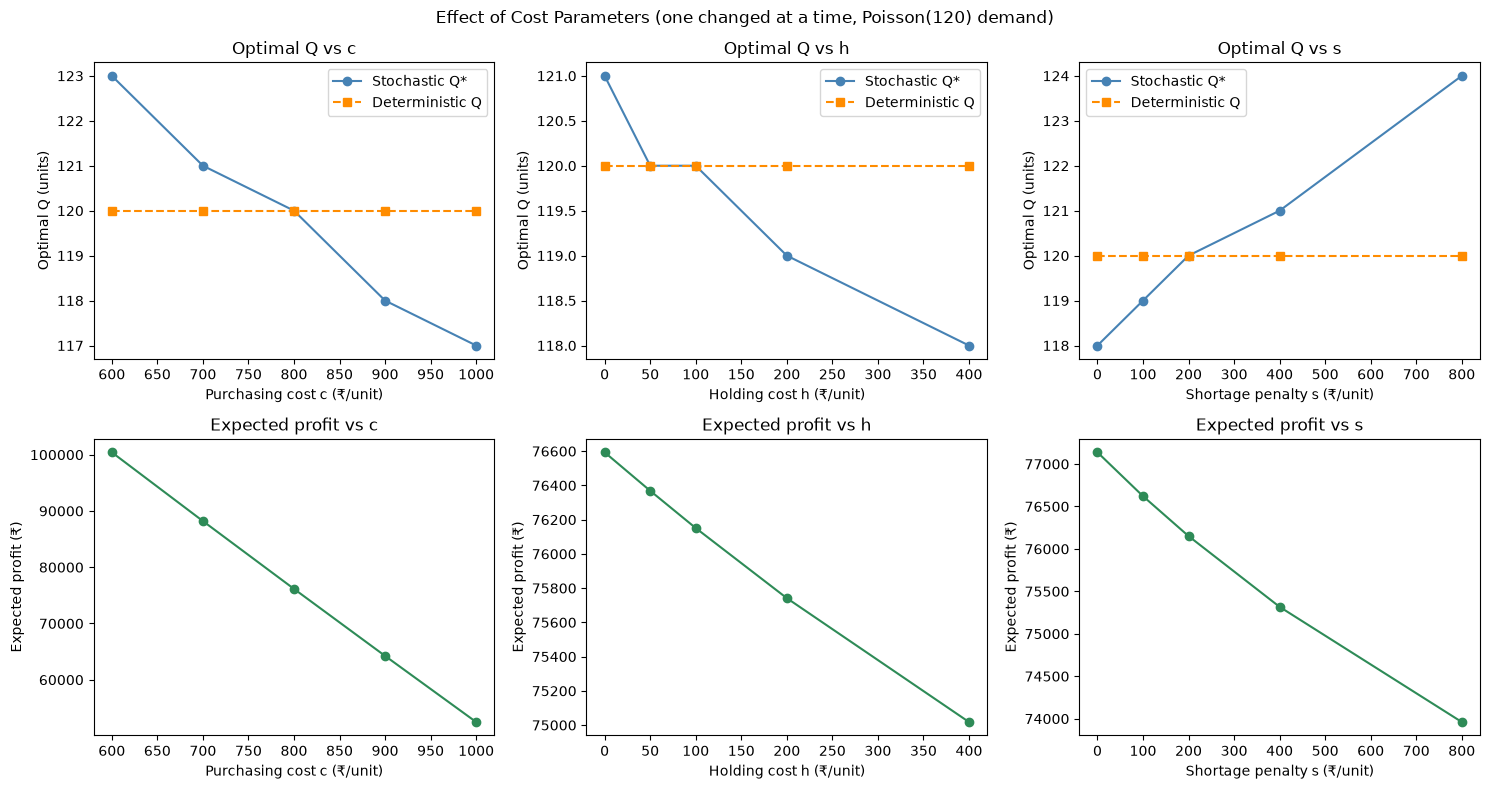

Saved 24 rows.


In [3]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append(os.path.abspath(".."))
from src.parameters import (COSTS, Q_MAX, N_SCENARIOS, SEED_TRAIN, SEED_TEST,
                            MEAN_DEMAND, MEAN_LEVELS, NB_VARIANCES)
from src.sensitivity import run_case

GRAPHS_DIR = os.path.join("..", "results", "graphs")
TABLES_DIR = os.path.join("..", "results", "tables")
OUT_DIR = os.path.join("..", "results", "experiment_outputs")
for folder in (GRAPHS_DIR, TABLES_DIR, OUT_DIR):
    os.makedirs(folder, exist_ok=True)


def run(label, dist, mean, var, costs):
    return run_case(label, dist, mean, var, costs, Q_MAX, N_SCENARIOS, SEED_TRAIN, SEED_TEST)


# Experiment A: mean demand
table_A = pd.DataFrame([run(f"mean {m}", "poisson", m, None, COSTS) for m in MEAN_LEVELS])
print("Largest training demand:", table_A["max_demand_train"].max(), "| Q_MAX =", Q_MAX)
assert table_A["max_demand_train"].max() < Q_MAX, "Capacity would be binding"
display(table_A[["mean_demand", "Q_star", "Q_theory", "Q_det", "test_profit_stoch",
                 "test_profit_det", "diff_stoch_minus_det", "stockout_freq_stoch"]].round(2))

# Experiment B: variability (mean fixed at 120)
variances = list(NB_VARIANCES.values()) + [960]
cases_B = [("Poisson (var 120)", "poisson", None)] + \
          [(f"NegBin (var {v})", "negbin", v) for v in variances]
table_B = pd.DataFrame([run(lbl, d, MEAN_DEMAND, v, COSTS) for lbl, d, v in cases_B])
display(table_B[["case", "demand_variance", "Q_star", "Q_theory", "Q_det",
                 "det_predicted_profit", "test_profit_stoch", "diff_stoch_minus_det",
                 "diff_ci95_half_width", "stockout_freq_stoch", "p5_profit_stoch"]].round(2))

# Experiment C: costs, one at a time
sweeps = {"c": [600, 700, 800, 900, 1000],
          "h": [0, 50, 100, 200, 400],
          "s": [0, 100, 200, 400, 800]}
rows_C = []
for param, values in sweeps.items():
    for v in values:
        costs = {**COSTS, param: v}
        row = run(f"{param} = {v}", "poisson", MEAN_DEMAND, None, costs)
        row["parameter"] = param
        row["value"] = v
        rows_C.append(row)
table_C = pd.DataFrame(rows_C)
display(table_C[["parameter", "value", "critical_ratio", "Q_star", "Q_theory", "Q_det",
                 "exp_profit_train", "test_profit_stoch", "test_profit_det",
                 "diff_stoch_minus_det", "diff_ci95_half_width"]].round(3))

# Graph A
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(table_A["mean_demand"], table_A["Q_star"], "o-", color="steelblue", label="Stochastic Q*")
axes[0].plot(table_A["mean_demand"], table_A["mean_demand"], "k--", label="Mean demand")
axes[0].set_title("Optimal Order Quantity vs Mean Demand")
axes[0].set_xlabel("Mean demand (units per period)")
axes[0].set_ylabel("Optimal Q* (units)")
axes[0].legend()
axes[1].plot(table_A["mean_demand"], table_A["test_profit_stoch"], "o-", color="seagreen")
axes[1].set_title("Expected Profit vs Mean Demand (independent test scenarios)")
axes[1].set_xlabel("Mean demand (units per period)")
axes[1].set_ylabel("Expected profit (₹)")
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "07_effect_of_mean_demand.png"), dpi=200)
plt.show()

# Graph B
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = table_B["demand_variance"]
axes[0].plot(x, table_B["Q_star"], "o-", color="steelblue", label="Stochastic Q*")
axes[0].plot(x, table_B["Q_det"], "s--", color="darkorange", label="Deterministic Q")
axes[0].set_title("Optimal Order Quantity vs Demand Variance (mean = 120)")
axes[0].set_xlabel("Demand variance (units²)")
axes[0].set_ylabel("Order quantity Q (units)")
axes[0].legend()
axes[1].plot(x, table_B["det_predicted_profit"], "s--", color="darkorange", label="Deterministic prediction")
axes[1].plot(x, table_B["test_profit_stoch"], "o-", color="seagreen", label="Average profit (test scenarios)")
axes[1].plot(x, table_B["p5_profit_stoch"], "^-", color="firebrick", label="5th percentile profit (test scenarios)")
axes[1].set_title("Profit vs Demand Variance (mean = 120)")
axes[1].set_xlabel("Demand variance (units²)")
axes[1].set_ylabel("Profit (₹)")
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "08_effect_of_demand_variability.png"), dpi=200)
plt.show()

# Graph C
labels = {"c": "Purchasing cost c (₹/unit)", "h": "Holding cost h (₹/unit)",
          "s": "Shortage penalty s (₹/unit)"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, param in enumerate(["c", "h", "s"]):
    sub = table_C[table_C["parameter"] == param]
    axes[0, j].plot(sub["value"], sub["Q_star"], "o-", color="steelblue", label="Stochastic Q*")
    axes[0, j].plot(sub["value"], sub["Q_det"], "s--", color="darkorange", label="Deterministic Q")
    axes[0, j].set_xlabel(labels[param])
    axes[0, j].set_ylabel("Optimal Q (units)")
    axes[0, j].set_title(f"Optimal Q vs {param}")
    axes[0, j].legend()
    axes[1, j].plot(sub["value"], sub["test_profit_stoch"], "o-", color="seagreen")
    axes[1, j].set_xlabel(labels[param])
    axes[1, j].set_ylabel("Expected profit (₹)")
    axes[1, j].set_title(f"Expected profit vs {param}")
plt.suptitle("Effect of Cost Parameters (one changed at a time, Poisson(120) demand)")
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "09_effect_of_cost_parameters.png"), dpi=200)
plt.show()

# Save tables
table_A.to_csv(os.path.join(OUT_DIR, "experiment_A_mean_demand.csv"), index=False)
table_B.to_csv(os.path.join(OUT_DIR, "experiment_B_variability.csv"), index=False)
table_C.to_csv(os.path.join(OUT_DIR, "experiment_C_costs.csv"), index=False)
summary_cols = ["case", "mean_demand", "demand_variance", "Q_star", "Q_theory", "Q_det",
                "test_profit_stoch", "test_profit_det", "diff_stoch_minus_det",
                "diff_ci95_half_width"]
summary = pd.concat([
    table_A[summary_cols].assign(experiment="A: mean demand"),
    table_B[summary_cols].assign(experiment="B: variability"),
    table_C[summary_cols].assign(experiment="C: costs"),
], ignore_index=True)
summary.round(2).to_csv(os.path.join(TABLES_DIR, "sensitivity_summary.csv"), index=False)
print("Saved", len(summary), "rows.")

In [4]:
table_A.to_csv(os.path.join(OUT_DIR, "experiment_A_mean_demand.csv"), index=False)
table_B.to_csv(os.path.join(OUT_DIR, "experiment_B_variability.csv"), index=False)
table_C.to_csv(os.path.join(OUT_DIR, "experiment_C_costs.csv"), index=False)

summary_cols = ["case", "mean_demand", "demand_variance", "Q_star", "Q_theory", "Q_det",
                "test_profit_stoch", "test_profit_det", "diff_stoch_minus_det",
                "diff_ci95_half_width"]
summary = pd.concat([
    table_A[summary_cols].assign(experiment="A: mean demand"),
    table_B[summary_cols].assign(experiment="B: variability"),
    table_C[summary_cols].assign(experiment="C: costs"),
], ignore_index=True)
summary.round(2).to_csv(os.path.join(TABLES_DIR, "sensitivity_summary.csv"), index=False)
print("Saved", len(summary), "rows.")

Saved 24 rows.


## Module 11 summary
- Each experiment changed one input at a time. Q* was chosen on training scenarios (seed 42) and policies were compared on independent test scenarios (seed 2026).
- Experiment A (mean demand 80 to 180): Q* equals the mean demand in every case and test profit rises from ₹49,596 to ₹116,375. The deterministic Q is the mean by construction, so the policies tie.
- Experiment B (mean fixed at 120, variance 120/240/480/960): Q* changes only from 120 to 117, but average test profit falls from ₹76,151 to ₹61,466 and 5th percentile profit from ₹55,200 to ₹11,500. The deterministic model predicts ₹84,000 in all cases.
- Experiment C (costs): Q* falls as c rises (123 to 117) and as h rises (121 to 118), and rises as s rises (118 to 124), matching the newsvendor critical ratio. Q* is within one unit of the theoretical Q in every case.
- The stochastic policy earns more than the deterministic one wherever Q* differs from 120, but the gains are small (about 0.04% to 0.65% of profit). The only difference not distinguishable from zero is h = 0.
- Main finding: demand variability and cost asymmetry change risk and profit more than they change the best order quantity. The deterministic model's main weakness is misjudging profit and risk, not choosing a very different Q.
- All parameter values are illustrative assumptions and demand is synthetic.

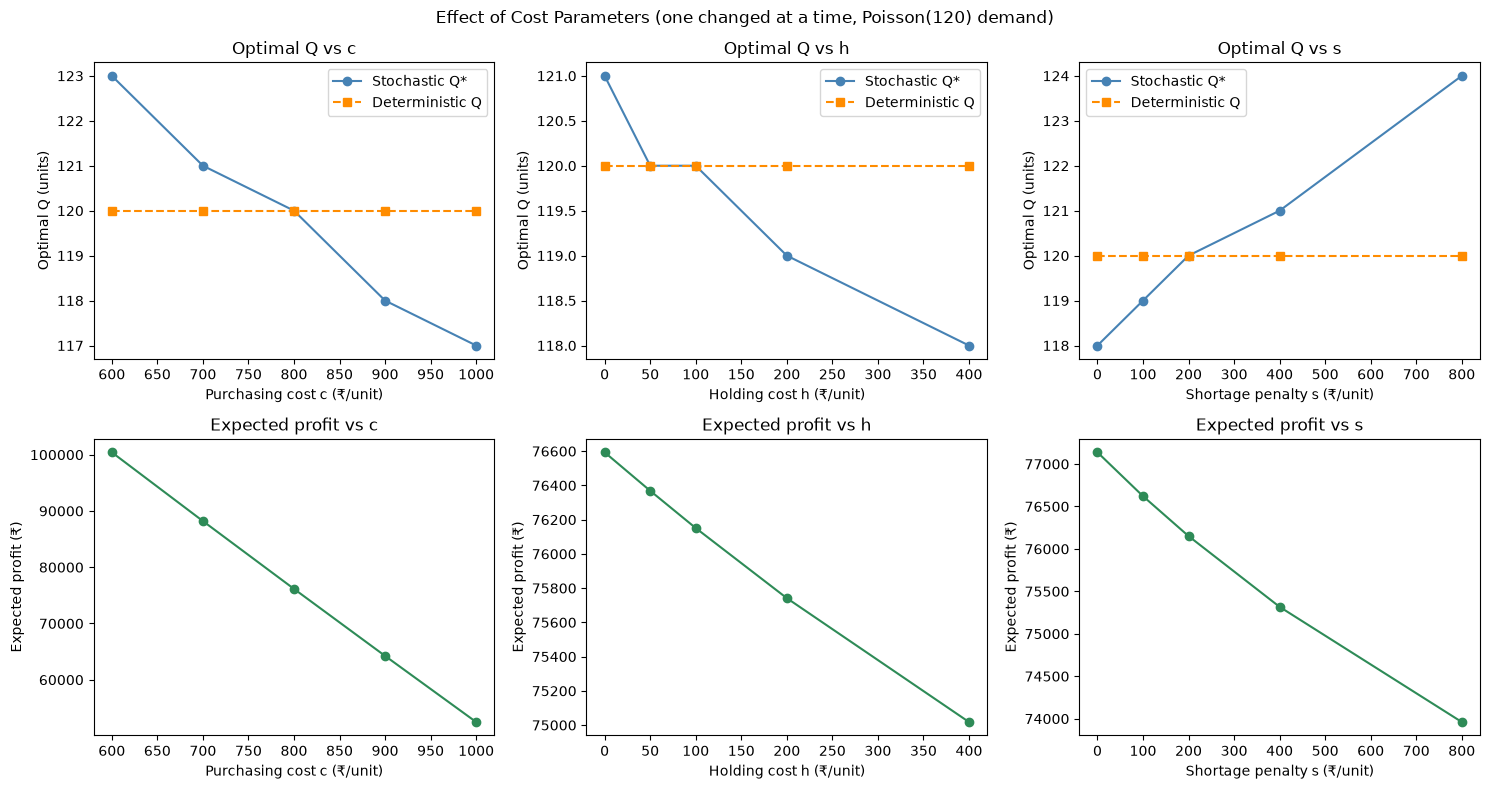

In [5]:
labels = {"c": "Purchasing cost c (₹/unit)",
          "h": "Holding cost h (₹/unit)",
          "s": "Shortage penalty s (₹/unit)"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, param in enumerate(["c", "h", "s"]):
    sub = table_C[table_C["parameter"] == param]

    axes[0, j].plot(sub["value"], sub["Q_star"], "o-", color="steelblue", label="Stochastic Q*")
    axes[0, j].plot(sub["value"], sub["Q_det"], "s--", color="darkorange", label="Deterministic Q")
    axes[0, j].set_xlabel(labels[param])
    axes[0, j].set_ylabel("Optimal Q (units)")
    axes[0, j].set_title(f"Optimal Q vs {param}")
    axes[0, j].legend()

    axes[1, j].plot(sub["value"], sub["test_profit_stoch"], "o-", color="seagreen")
    axes[1, j].set_xlabel(labels[param])
    axes[1, j].set_ylabel("Expected profit (₹)")
    axes[1, j].set_title(f"Expected profit vs {param}")

plt.suptitle("Effect of Cost Parameters (one changed at a time, Poisson(120) demand)")
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "09_effect_of_cost_parameters.png"), dpi=200)
plt.show()

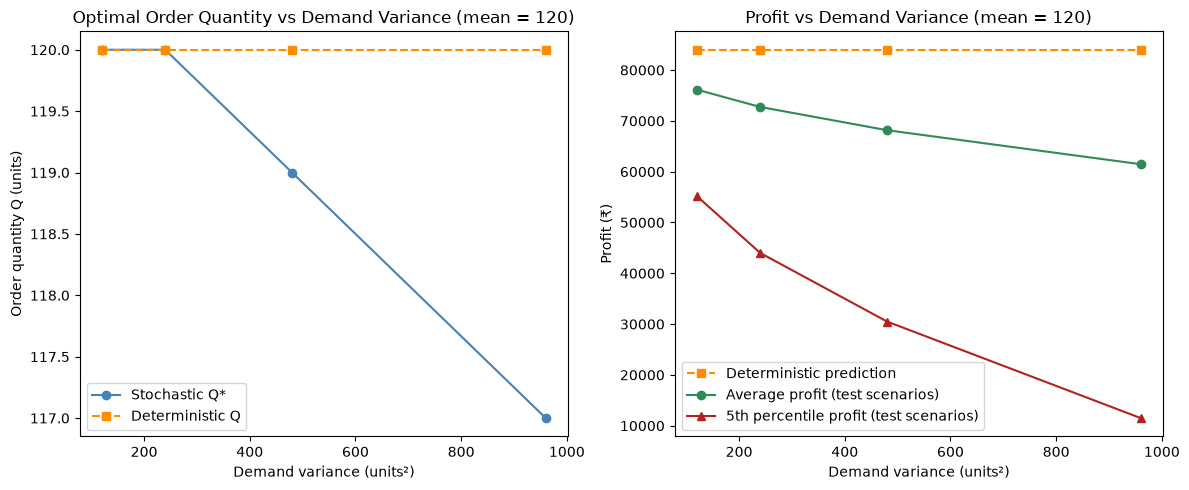

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = table_B["demand_variance"]

axes[0].plot(x, table_B["Q_star"], "o-", color="steelblue", label="Stochastic Q*")
axes[0].plot(x, table_B["Q_det"], "s--", color="darkorange", label="Deterministic Q")
axes[0].set_title("Optimal Order Quantity vs Demand Variance (mean = 120)")
axes[0].set_xlabel("Demand variance (units²)")
axes[0].set_ylabel("Order quantity Q (units)")
axes[0].legend()

axes[1].plot(x, table_B["det_predicted_profit"], "s--", color="darkorange",
             label="Deterministic prediction")
axes[1].plot(x, table_B["test_profit_stoch"], "o-", color="seagreen",
             label="Average profit (test scenarios)")
axes[1].plot(x, table_B["p5_profit_stoch"], "^-", color="firebrick",
             label="5th percentile profit (test scenarios)")
axes[1].set_title("Profit vs Demand Variance (mean = 120)")
axes[1].set_xlabel("Demand variance (units²)")
axes[1].set_ylabel("Profit (₹)")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "08_effect_of_demand_variability.png"), dpi=200)
plt.show()

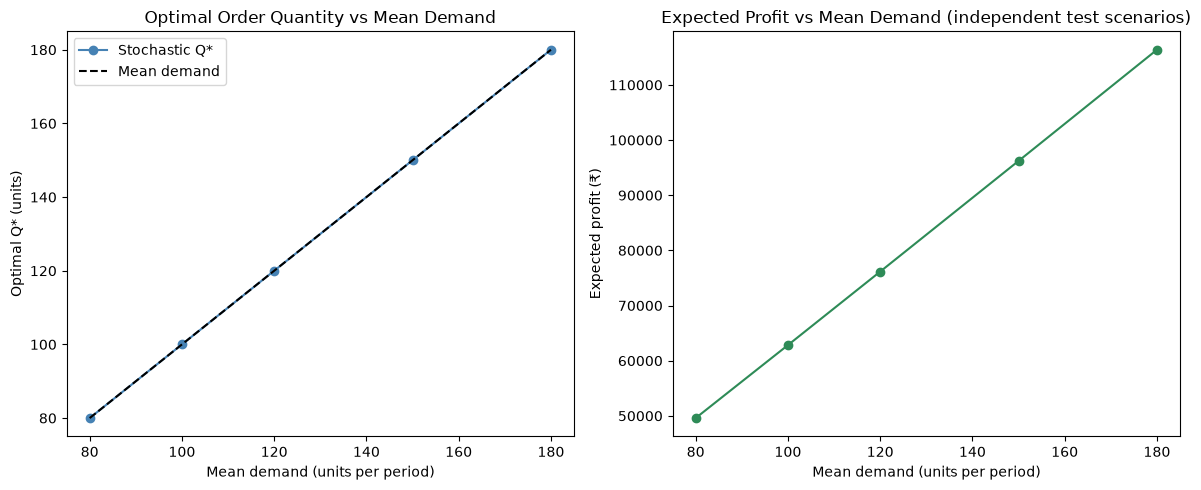

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(table_A["mean_demand"], table_A["Q_star"], "o-", color="steelblue", label="Stochastic Q*")
axes[0].plot(table_A["mean_demand"], table_A["mean_demand"], "k--", label="Mean demand")
axes[0].set_title("Optimal Order Quantity vs Mean Demand")
axes[0].set_xlabel("Mean demand (units per period)")
axes[0].set_ylabel("Optimal Q* (units)")
axes[0].legend()

axes[1].plot(table_A["mean_demand"], table_A["test_profit_stoch"], "o-", color="seagreen")
axes[1].set_title("Expected Profit vs Mean Demand (independent test scenarios)")
axes[1].set_xlabel("Mean demand (units per period)")
axes[1].set_ylabel("Expected profit (₹)")

plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, "07_effect_of_mean_demand.png"), dpi=200)
plt.show()

In [8]:
sweeps = {
    "c": [600, 700, 800, 900, 1000],    # purchasing cost (base 800)
    "h": [0, 50, 100, 200, 400],        # holding cost (base 100)
    "s": [0, 100, 200, 400, 800],       # shortage penalty (base 200)
}

rows_C = []
for param, values in sweeps.items():
    for v in values:
        costs = {**COSTS, param: v}                     # change only one parameter
        row = run(f"{param} = {v}", "poisson", MEAN_DEMAND, None, costs)
        row["parameter"] = param
        row["value"] = v
        rows_C.append(row)

table_C = pd.DataFrame(rows_C)

table_C[["parameter", "value", "critical_ratio", "Q_star", "Q_theory", "Q_det",
         "exp_profit_train", "test_profit_stoch", "test_profit_det",
         "diff_stoch_minus_det", "diff_ci95_half_width"]].round(3)

,parameter,value,critical_ratio,Q_star,Q_theory,Q_det,exp_profit_train,test_profit_stoch,test_profit_det,diff_stoch_minus_det,diff_ci95_half_width
0,c,600,0.611,123,123,120,100495.72,100425.08,100151.06,274.02,50.855
1,c,700,0.556,121,121,120,88259.24,88205.52,88151.06,54.46,17.618
2,c,800,0.500,120,120,120,76195.60,76151.06,76151.06,0.00,0.000
3,c,900,0.444,118,118,120,64269.24,64242.34,64151.06,91.28,34.590
4,c,1000,0.389,117,117,120,52510.48,52490.24,52151.06,339.18,50.948
5,h,0,0.529,121,121,120,76644.56,76593.41,76586.42,6.99,16.639
6,h,50,0.514,120,120,120,76412.25,76368.74,76368.74,0.00,0.000
7,h,100,0.500,120,120,120,76195.60,76151.06,76151.06,0.00,0.000
8,h,200,0.474,119,119,120,75777.34,75741.76,75715.70,26.06,18.615
9,h,400,0.429,118,118,120,75048.28,75018.14,74844.98,173.16,40.355


In [9]:
variances = list(NB_VARIANCES.values()) + [960]        # 240, 480 and an extra 960
cases_B = [("Poisson (var 120)", "poisson", None)] + \
          [(f"NegBin (var {v})", "negbin", v) for v in variances]

table_B = pd.DataFrame([run(label, d, MEAN_DEMAND, v, COSTS) for label, d, v in cases_B])

table_B[["case", "demand_variance", "Q_star", "Q_theory", "Q_det", "det_predicted_profit",
         "test_profit_stoch", "diff_stoch_minus_det", "diff_ci95_half_width",
         "stockout_freq_stoch", "p5_profit_stoch"]].round(2)

,case,demand_variance,Q_star,Q_theory,Q_det,det_predicted_profit,test_profit_stoch,diff_stoch_minus_det,diff_ci95_half_width,stockout_freq_stoch,p5_profit_stoch
0,Poisson (var 120),120,120,120,120,84000.0,76151.06,0.00,0.00,0.47,55200.0
1,NegBin (var 240),240,120,119,120,84000.0,72737.72,0.00,0.00,0.47,44000.0
2,NegBin (var 480),480,119,119,120,84000.0,68163.92,26.82,17.63,0.49,30500.0
3,NegBin (var 960),960,117,118,120,84000.0,61466.32,102.42,52.29,0.49,11500.0


In [10]:
table_A = pd.DataFrame([run(f"mean {m}", "poisson", m, None, COSTS) for m in MEAN_LEVELS])

print("Largest training demand:", table_A["max_demand_train"].max(), "| Q_MAX =", Q_MAX)
assert table_A["max_demand_train"].max() < Q_MAX, "Capacity would be binding"

table_A[["mean_demand", "Q_star", "Q_theory", "Q_det", "test_profit_stoch",
         "test_profit_det", "diff_stoch_minus_det", "stockout_freq_stoch"]].round(2)

Largest training demand: 229 | Q_MAX = 500


,mean_demand,Q_star,Q_theory,Q_det,test_profit_stoch,test_profit_det,diff_stoch_minus_det,stockout_freq_stoch
0,80,80,80,80,49596.22,49596.22,0.0,0.47
1,100,100,100,100,62827.36,62827.36,0.0,0.47
2,120,120,120,120,76151.06,76151.06,0.0,0.47
3,150,150,150,150,96218.82,96218.82,0.0,0.48
4,180,180,180,180,116375.48,116375.48,0.0,0.48


In [11]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(".."))
from src.parameters import (COSTS, Q_MAX, N_SCENARIOS, SEED_TRAIN, SEED_TEST,
                            MEAN_DEMAND, MEAN_LEVELS, NB_VARIANCES)
from src.sensitivity import run_case

GRAPHS_DIR = os.path.join("..", "results", "graphs")
TABLES_DIR = os.path.join("..", "results", "tables")
OUT_DIR = os.path.join("..", "results", "experiment_outputs")


def run(label, dist, mean, var, costs):
    return run_case(label, dist, mean, var, costs, Q_MAX, N_SCENARIOS, SEED_TRAIN, SEED_TEST)


print("Base costs:", COSTS)
print("Mean demand levels:", MEAN_LEVELS)

Base costs: {'p': 1500, 'c': 800, 'h': 100, 's': 200}
Mean demand levels: [80, 100, 120, 150, 180]
